# Tutorial 05: tides

With tides switched on (flowchart `pipeline_tides_steps.png`), the changes relative to the previous chapters are:

| Section | Source | Change |
|---|---|---|
| 1 | `__init__`: `self.kappa` | one more column label: the $\kappa_2^T$ nodes $\kappa_c$ |
| 2 | `_split_nodes`, `_build_table`, `_table_column` | NRTidalv3 needs a second label, the share $w_j$ of the heavier star in $\kappa_2^T$ (four nodes per $q$); each column calls LAL with $\kappa_c$ split as $w_j$ |
| 3 | SVD block | the columns become $(s,c,j)$; the rank grows substantially |
| 4 | end of `__init__`: `_m1c, _m2c, _kc1, _kc2` | component masses and $c_{1,2}(q)$ of every **source-frame** cell |
| 5 | `_tide_weights`, `_kappa_weights`, `_split_weights` | every call: EOS → $\Lambda$ → $\kappa_{\ell s}$ and $w_{\ell s}$ → interpolation weights $W_{\ell s,cj}$ (cubic in $\ln\kappa$ and in $w$) |
| 6 | `omega()`: `einsum("lq,lqk,rqk->lr")` | contract $q$ and the tide nodes together, **before the redshift convolution** |

Notation: $\ell$ = source-frame $\ln M$, $s$ = $q$ node, $c$ = κ node, $j$ = split node, $r$ = SVD mode.

We use a BNS set-up: total mass 1.8–6 $M_\odot$, $q\ge0.3$, 41 $q$ nodes, the waveform `IMRPhenomXAS_NRTidalv3`, no spins. With `IMRPhenomXAS_NRTidalv2` everything below holds with a single split node ($\Lambda_1/\Lambda_2=q^6$, exact for v2), and the $w$ weights drop out.

In [1]:
import os
for k in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ[k] = "1"

In [2]:
%matplotlib inline
import sys
sys.path.append("../")
FIGDIR = "../../Figures/"

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set(style='ticks', context='notebook', font='serif', 
        font_scale=1.5, palette='deep')
plt.rcParams.update({
    "text.usetex": True,
    "text.latex.preamble": r"\usepackage{amssymb}\usepackage{mathrsfs}\usepackage{bm}", 
    "font.family": "serif",
    'backend': 'pdf',
    # Grid
    "axes.grid": True,
    "grid.alpha": 0.7,
    "grid.linewidth": 0.4,

    # Ticks
    "xtick.direction": "in",
    "ytick.direction": "in",
    'xtick.labelsize': 18,
    'ytick.labelsize': 18,
    # Font
    'font.size': 18,
    'legend.fontsize': 18,
})
import jax
jax.config.update("jax_enable_x64", True)
import jax.numpy as jnp

from stochaxtic import jax_populations as jp
from stochaxtic.fast_omega import (FastOmega, T_SUN, A_PRE, DEFAULT_N_SUB, OMEGA_REL_CUT,
                                   SPLIT_FRACTIONS, _fix_signs)
from stochaxtic.constants import H0_SI

def check(name, mine, ref):
    mine, ref = np.asarray(mine), np.asarray(ref)
    assert mine.shape == ref.shape, (name, mine.shape, ref.shape)
    rel = np.max(np.abs(mine - ref)) / np.max(np.abs(ref))
    print(f"{name:30s} shape {str(ref.shape):16s} max |diff| / max |ref| = {rel:.1e}")
    return rel

fo = FastOmega(waveform="IMRPhenomXAS_NRTidalv3", tides=True, m_tot_range=(1.8, 6.0), q_min=0.3, n_q=41)
n_q, n_k, n_w = fo.info["n_q"], fo.info["n_kappa"], fo.info["n_split"]
d = fo.info["delta"]
{k: fo.info[k] for k in ("n_lnM", "n_q", "n_kappa", "n_split", "n_columns", "rank", "m_ref", "x_ref")}

FastOmega: SVD loaded from /home/haowen.zhong/.cache/stochaxtic/svd_IMRPhenomXAS_NRTidalv3_c34abe262c34afef.npz
FastOmega: IMRPhenomXAS_NRTidalv3, spins=None, tides=True: 3936 table columns, rank 85; grids lnM 242, z 444, lnq 41, lnf 1061; setup 0.1 s


{'n_lnM': 242,
 'n_q': 41,
 'n_kappa': 24,
 'n_split': 4,
 'n_columns': 3936,
 'rank': 85,
 'm_ref': 2.8,
 'x_ref': 0.0003}

## 1. The κ nodes

$\kappa_1=0$ (no tides; also the black-hole value), plus 23 nodes log-spaced on $[0.1,3000]$. Why a separate 0, and nodes that are dense from 0.1 upwards? NRTidal's tidal taper frequency depends on κ (roughly as a power of κ), so $J$ is very non-linear in κ but smooth in $\ln\kappa$: log-spaced nodes, and an interpolation in $\ln\kappa$ (section 5).

In [4]:
kappa = np.concatenate([[0.0], np.geomspace(0.1, 3000.0, n_k - 1)])
check("kappa nodes", kappa, fo.kappa)
print(np.round(kappa, 2))

kappa nodes                    shape (24,)            max |diff| / max |ref| = 0.0e+00
[0.00000e+00 1.00000e-01 1.60000e-01 2.60000e-01 4.10000e-01 6.50000e-01
 1.04000e+00 1.66000e+00 2.66000e+00 4.25000e+00 6.78000e+00 1.08400e+01
 1.73200e+01 2.76700e+01 4.42200e+01 7.06400e+01 1.12870e+02 1.80340e+02
 2.88130e+02 4.60360e+02 7.35540e+02 1.17520e+03 1.87765e+03 3.00000e+03]


## 2. A column $(s,c,j)$: making $\kappa_{\rm eff}^T=\kappa_c$ with the share $w_j$

For $\Omega_{\rm GW}$ (only $|h|^2$ counts) an NRTidal model depends on two tidal numbers:
- its amplitude correction, on $\kappa_{\rm eff}^T=c_1(q)\Lambda_1+c_2(q)\Lambda_2$;
- its merger frequency, where the waveform is tapered to zero. NRTidalv2 takes it from $\kappa_{\rm eff}^T$ as well, so for v2 $\kappa_{\rm eff}^T$ alone labels a column. NRTidalv3 takes it from $\kappa_2^T\equiv3(X_2X_1^4\Lambda_1+X_1X_2^4\Lambda_2)$ (arXiv:2311.07456), a different combination unless $m_1=m_2$.

So a v3 column needs a second label. FastOmega uses the share of the heavier star, $w=c_1\Lambda_1/\kappa_{\rm eff}^T$: with $\Lambda_1=w\kappa_c/c_1$ and $\Lambda_2=(1-w)\kappa_c/c_2$ a column has exactly $\kappa_{\rm eff}^T=\kappa_c$ for any $w$, and $\kappa_2^T$ is linear in $w$. For one EOS $\Lambda(m)$ decreases with mass, so $\Lambda_1\le\Lambda_2$ and
$$0\le w\le w_0(q)=\frac{c_1}{c_1+c_2}$$
($w=0$: the heavier star is above the maximum NS mass, $\Lambda_1=0$; $w=w_0$: $\Lambda_1=\Lambda_2$). The split nodes are the fractions $0,\tfrac13,\tfrac23,1$ of $w_0$ (`SPLIT_FRACTIONS`, `_split_nodes`), so every EOS lies inside them and is interpolated, never extrapolated. There is **no EOS** here: the table is computed for every possible $(\kappa,w)$.

$$c_1=\tfrac{3}{13}\Big(1+12\tfrac{X_2}{X_1}\Big)X_1^5,\quad c_2=\tfrac{3}{13}\Big(1+12\tfrac{X_1}{X_2}\Big)X_2^5,\qquad X_1=\tfrac{1}{1+q},\ X_2=\tfrac{q}{1+q}.$$

The reference mass is $m_{\rm ref}=2.8\,M_\odot$ (a typical BNS); the columns are stored in `J[s, c, j]`.

In [6]:
from stochaxtic.orientation import OrientationAverager
J_cached = fo.table()[..., 0, :]             # spin axis dropped: (n_q, n_kappa, n_split, n_xJ)
print("cached table:", J_cached.shape)

# the split nodes: the fractions 0, 1/3, 2/3, 1 of w0 = c1 / (c1 + c2)
kc1, kc2 = jp.kappa2T_coefficients(np.exp(fo.lq))            # unclamped q, as in _build_table
wn = np.asarray(SPLIT_FRACTIONS)[None, :] * (kc1 / (kc1 + kc2))[:, None]        # (n_q, n_split)
check("split nodes  ->  fo._wnodes", wn, fo._wnodes)

avg = OrientationAverager("IMRPhenomXAS_NRTidalv3")
m_ref, x_ref = fo.info["m_ref"], fo.info["x_ref"]
xJ = np.exp(fo.ln_xJ); live = xJ < 1.0

def my_column(s, c, j):
    # q, kappa, w
    q = min(np.exp(fo.lq[s]), 1.0 - 1e-6)
    m1, m2 = m_ref / (1 + q), m_ref * q / (1 + q)
    lam = (wn[s, j] * kappa[c] / kc1[s], (1 - wn[s, j]) * kappa[c] / kc2[s])
    assert abs(kc1[s] * lam[0] + kc2[s] * lam[1] - kappa[c]) <= 1e-12 * max(kappa[c], 1)   # kappa2T = kappa_c
    col = np.zeros(len(xJ))
    col[live] = avg(xJ[live] / (m_ref * T_SUN), m1, m2, (0, 0, 0), (0, 0, 0),
                    f_ref=x_ref / (m_ref * T_SUN), lambdas=lam) / m_ref ** 4
    return col

for s, c, j in ((0, 0, 0), (0, 14, 1), (20, 12, 2), (40, 23, 3)):
    check(f"J column (s={s}, c={c}, j={j})", my_column(s, c, j), J_cached[s, c, j])

cached table: (41, 24, 4, 876)
split nodes  ->  fo._wnodes    shape (41, 4)          max |diff| / max |ref| = 1.1e-16
J column (s=0, c=0, j=0)       shape (876,)           max |diff| / max |ref| = 0.0e+00
J column (s=0, c=14, j=1)      shape (876,)           max |diff| / max |ref| = 0.0e+00
J column (s=20, c=12, j=2)     shape (876,)           max |diff| / max |ref| = 0.0e+00
J column (s=40, c=23, j=3)     shape (876,)           max |diff| / max |ref| = 0.0e+00


/home/haowen.zhong/StochAXtic/StochAXtic/tutorials/../stochaxtic/orientation.py:103: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  import lal


How κ changes a column: the ratio to the column with $\kappa=0$ (at $q=1$, where the share does not matter). The larger κ, the earlier the tidal taper (at smaller $x$). This dependence on κ is what gets interpolated later.

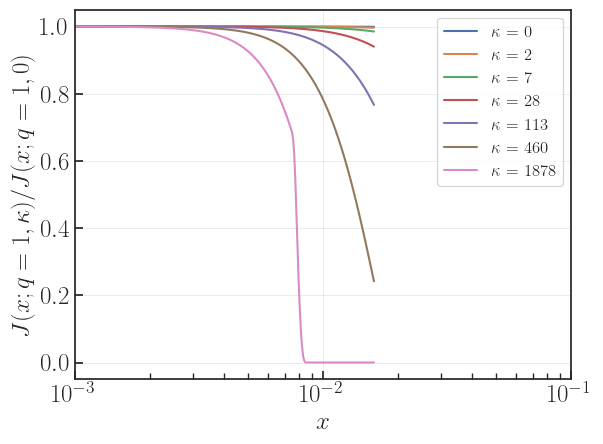

In [7]:
s = n_q - 1                                                      # q = 1
base = J_cached[s, 0, -1]
ok = base > 1e-6 * base.max()
for c in range(4, n_k, 3):
    plt.semilogx(xJ[ok], J_cached[s, c, -1][ok] / base[ok], label=rf"$\kappa$ = {kappa[c]:.0f}")
plt.xlim(1e-3, 0.1) 
plt.xlabel(r"$x$") 
plt.ylabel(r"$J(x; q=1, \kappa) / J(x; q=1, 0)$") 
plt.legend(fontsize=12);

And how the share changes a column, at fixed $\kappa_{\rm eff}^T$. It moves only the merger frequency, so the columns agree up to the taper and then end at different $x$ (the taper ends at 1.2 times the merger frequency). Plotted is $Jx^{7/3}$, flat in the inspiral. From $w=0$ to $w_0$ the merger frequency moves by a few per cent at $q=0.3$ (up to ~6% at small κ), less towards equal masses and at large κ, and not at all at $q=1$, where $X_1=X_2$ makes the $\kappa_2^T$ proportional to $\kappa_{\rm eff}^T$. 

q = 0.30: last x with J > 0 for w/w0 = 0, 1/3, 2/3, 1: [0.0144 0.0145 0.0147 0.015 ]
q = 1.00: last x with J > 0 for w/w0 = 0, 1/3, 2/3, 1: [0.0357 0.0357 0.0357 0.0357]


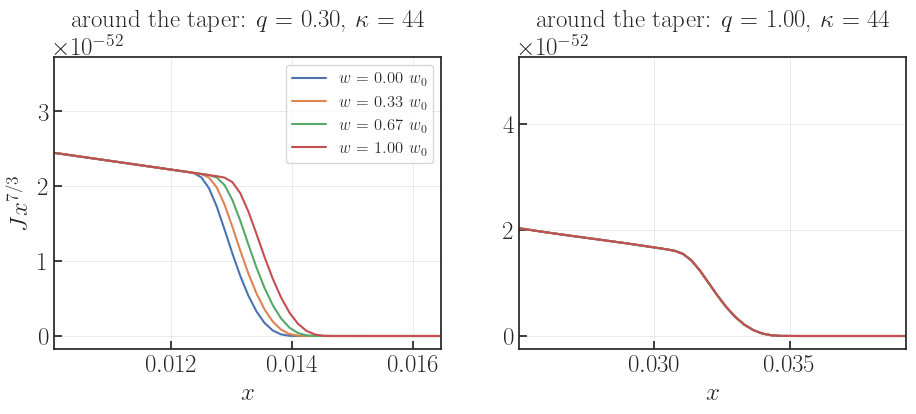

In [8]:
c = 14                                                           # kappa = 44
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for a, s in zip(ax, (0, n_q - 1)):
    ends = [xJ[J_cached[s, c, j] > 0][-1] for j in range(n_w)]   # where the taper reaches 0
    print(f"q = {np.exp(fo.lq[s]):.2f}: last x with J > 0 for w/w0 = 0, 1/3, 2/3, 1:", np.round(ends, 4))
    for j in range(n_w):
        a.plot(xJ, J_cached[s, c, j] * xJ ** (7 / 3), label=rf"$w$ = {SPLIT_FRACTIONS[j]:.2f} $w_0$")
    a.set(xlim=(0.7 * ends[0], 1.1 * ends[-1]), xlabel=r"$x$",
          title=rf"around the taper: $q$ = {np.exp(fo.lq[s]):.2f}, $\kappa$ = {kappa[c]:.0f}")
ax[0].set_ylabel(r"$J x^{7/3}$")
ax[0].legend(fontsize=12)

## 3. SVD: columns $(s,c,j)$, larger rank

The column order $(s,c,j)$ is set by `reshape` (κ before the split: the tide nodes are flattened κ-major). The column weights are $\sqrt{w_s}$, **without** $1/(n_\kappa n_{\rm split})$: a binary uses only the few tide nodes around its own $(\kappa,w)$ (with weights summing to 1), instead of an average over all samples as for spins.

In [9]:
A = J_cached.reshape(-1, len(fo.ln_xJ)).T                       # columns (s, c, j)
sx = np.sqrt(np.mean(A ** 2, axis=1))
An = np.where(sx[:, None] > 0, A / np.where(sx > 0, sx, 1.0)[:, None], 0.0)
colw = np.sqrt(np.repeat(fo.wq, n_k * n_w))                     # n_spin = 1
u, sv, vt = np.linalg.svd(An * colw[None, :], full_matrices=False)
rank = int(min(96, max(1, np.sum(sv / sv[0] > 1e-4))))
_, vt_r = _fix_signs(u[:, :rank] * sv[:rank], vt[:rank])         # FastOmega's sign convention
coef = (vt_r / colw[None, :]).reshape(rank, n_q, n_k * n_w, 1)   # tide nodes (c, j) in one axis
print("rank =", rank, "(fo:", fo.info["rank"], ")")
check("coef  ->  fo._C", coef, fo._C)

rank = 85 (fo: 85 )
coef  ->  fo._C                shape (85, 41, 96, 1)  max |diff| / max |ref| = 1.8e-12


np.float64(1.7647240217257856e-12)

The rank is 85 (8 for BBH without tides; 83 for NRTidalv2 on the same grid): the position of the tidal taper moves with κ, and such "moving steps" need many modes. The split axis quadruples the columns but adds only two modes: it moves the same taper, by a few per cent.

## 4. Component masses of the source-frame cells

The EOS gives $\Lambda(m_{\rm src})$, so we need the $m_1,m_2$ of every source-frame cell $(\ell,s)$ (at the cell centre), and $c_{1,2}(q_s)$. None of these depends on hyperparameters, so they are computed in the constructor.

In [10]:
M = np.exp(fo.l_src)[:, None]
q = np.exp(fo.lq)[None, :]
m1c, m2c = M / (1 + q), M * q / (1 + q)
check("m1 of cells  ->  fo._m1c", m1c, fo._m1c)
check("m2 of cells  ->  fo._m2c", m2c, fo._m2c)
check("c1(q)  ->  fo._kc1", np.asarray(kc1)[None, :], fo._kc1)

m1 of cells  ->  fo._m1c       shape (242, 41)        max |diff| / max |ref| = 0.0e+00
m2 of cells  ->  fo._m2c       shape (242, 41)        max |diff| / max |ref| = 0.0e+00
c1(q)  ->  fo._kc1             shape (1, 41)          max |diff| / max |ref| = 0.0e+00


np.float64(0.0)

## 5. Every call: EOS → $\kappa_{\ell s}$, $w_{\ell s}$ → interpolation weights $W_{\ell s,cj}$

1. **EOS**: $\ln\Lambda=\ln\Lambda_{1.4}+b_1\ln\frac{m}{1.4}+b_2\ln^2\frac{m}{1.4}$, and $\Lambda=0$ for $m>m_{\rm NS,max}$ (a logistic soft edge of width one cell $\delta$, for differentiability);
2. $\kappa_{\ell s}=c_1\Lambda(m_{1,\ell s})+c_2\Lambda(m_{2,\ell s})$;
3. **find the interval**: the $c$ with $\kappa_c\le\kappa_{\ell s}<\kappa_{c+1}$, searched in $\ln\kappa$; $\kappa<0.1$ falls in the first interval $[0,0.1]$;
4. **weights**. The simplest choice (`kappa_interp="linear"`) are hat weights, linear in κ: $\varphi=\frac{\kappa_{\ell s}-\kappa_c}{\kappa_{c+1}-\kappa_c}$, $W^\kappa_{\ell sc}=1-\varphi$, $W^\kappa_{\ell s,c+1}=\varphi$. Its error is $O(h^2)$ in the node spacing and reaches 1.4% at 1 kHz for BNS with 24 nodes. The default (`kappa_interp="cubic"`) interpolates in $u=\ln\kappa$, where $J$ is smooth: the 4-point Lagrange weights on the log nodes around the interval (shifted inwards at the ends of the grid),
$$W^\kappa_{\ell sc}=\prod_{c'\neq c}\frac{u_{\ell s}-u_{c'}}{u_c-u_{c'}},$$
with error $O(h^4)$: $\le5\times10^{-5}$ below 1 kHz with the same 24 nodes. Below the first log node ($\kappa<0.1$, where $\ln\kappa$ is undefined at 0) it stays linear in κ, which is exact for the linear small-κ response.

5. **the share** $w_{\ell s}=c_1\Lambda(m_{1,\ell s})/\kappa_{\ell s}$ (0 where $\kappa_{\ell s}=0$), and its Lagrange weights $W^w_{\ell sj}$ on the four split nodes of $q_s$ (`_split_weights`; cubic, and inside $[0,w_0]$ for any EOS);
6. a tide node is the pair $(\kappa_c,w_j)$, flattened κ-major, and its weight is the product $W_{\ell s,cj}=W^\kappa_{\ell sc}\,W^w_{\ell sj}$, at most $4\times4=16$ non-zero per cell.

Both κ rules are linear in the table, sum to one, and keep the gradients; so do the split weights and their product. With NRTidalv2 there is a single split node, and $W_{\ell s,c}=W^\kappa_{\ell sc}$.


In [11]:
d

0.005

In [12]:
fnt, tp_default = jp.TIDE_MODELS["eos_lnpoly"]
print("EOS defaults:", tp_default)
lk0, dlk = np.log(kappa[1]), np.log(kappa[2] / kappa[1])
kn = jnp.asarray(kappa)

def kappa_cells(tp):                                        # kappa_ls and the heavier star's part c1 Lambda(m1)
    k1 = kc1[None, :] * fnt(jnp.asarray(m1c), tp, d)
    return k1 + kc2[None, :] * fnt(jnp.asarray(m2c), tp, d), k1

def my_hat_weights(kap):                                    # kappa_interp = "linear"
    kc = jnp.clip(kap, 0.0, kappa[-1])
    lk = jnp.log(jnp.maximum(kc, kappa[1]))
    i0 = jnp.where(kc < kappa[1], 0, 1 + jnp.floor((lk - lk0) / dlk).astype(jnp.int32))
    i0 = jnp.clip(i0, 0, n_k - 2)
    phi = jnp.clip((kc - kn[i0]) / (kn[i0 + 1] - kn[i0]), 0.0, 1.0)
    return (1.0 - phi)[..., None] * jax.nn.one_hot(i0, n_k) + phi[..., None] * jax.nn.one_hot(i0 + 1, n_k), kc, lk, i0

def my_kappa_weights(kap):                                  # kappa_interp = "cubic" (default)
    lin, kc, lk, i0 = my_hat_weights(kap)
    s = jnp.clip(i0 - 1, 1, n_k - 4)                        # log nodes s .. s+3
    t = (lk - lk0) / dlk - (s - 1)                          # node s at t = 0, spacing 1
    w = jnp.stack([-(t - 1) * (t - 2) * (t - 3) / 6, t * (t - 2) * (t - 3) / 2,
                   -t * (t - 1) * (t - 3) / 2, t * (t - 1) * (t - 2) / 6], axis=-1)
    cub = jnp.einsum("lsj,lsjk->lsk", w, jax.nn.one_hot(s[..., None] + jnp.arange(4), n_k))
    return jnp.where((kc < kappa[1])[..., None], lin, cub)

def my_split_weights(w):                                    # Lagrange in w on the n_split nodes of each q
    x = jnp.clip(w, 0.0, 1.0)
    out = []
    for i in range(n_w):
        wi = jnp.ones_like(x)
        for j in range(n_w):
            if j != i:
                wi = wi * (x - wn[None, :, j]) / (wn[:, i] - wn[:, j])[None, :]
        out.append(wi)
    return jnp.stack(out, axis=-1)                          # (l, s, n_split)

def my_tide_weights(tp, interp="cubic"):
    kap, k1 = kappa_cells(tp)
    Wk = my_hat_weights(kap)[0] if interp == "linear" else my_kappa_weights(kap)
    w = k1 / jnp.where(kap > 0, kap, 1.0)                   # share of the heavier star
    Ww = my_split_weights(w)
    return (Wk[..., :, None] * Ww[..., None, :]).reshape(kap.shape + (-1,)), kap, w   # kappa-major

fo.kappa_interp = "linear"                                  # compare the hat weights first
check("W (linear) ->  _tide_weights", my_tide_weights(tp_default, "linear")[0],
      fo._tide_weights("eos_lnpoly", tp_default))
fo.kappa_interp = "cubic"
W, kap, w = my_tide_weights(tp_default)
check("W (cubic)  ->  _tide_weights", W, fo._tide_weights("eos_lnpoly", tp_default))
print("sum W = 1 everywhere:", bool(np.allclose(W.sum(-1), 1.0)), "  nonzero per cell <= 16:",
      int((np.abs(np.asarray(W)) > 0).sum(-1).max()))
w_rel = np.asarray(w) / wn[None, :, -1]                     # w / w0
print(f"w / w0 of the NS cells: {w_rel[np.asarray(kap) > 0].min():.3f} ... {w_rel[np.asarray(kap) > 0].max():.3f}"
      "  (inside the split nodes [0, 1])")

EOS defaults: {'Lambda_14': 400.0, 'b1': -6.0, 'b2': -3.0, 'm_NS_max': 2.3}
W (linear) ->  _tide_weights   shape (242, 41, 96)    max |diff| / max |ref| = 5.3e-16
W (cubic)  ->  _tide_weights   shape (242, 41, 96)    max |diff| / max |ref| = 5.3e-16
sum W = 1 everywhere: True   nonzero per cell <= 16: 16
w / w0 of the NS cells: 0.000 ... 1.000  (inside the split nodes [0, 1])


Pick one cell and look at the numbers ($M_{\rm src}\approx2.89$, $q\approx0.74$):

M_src = 2.894, q = 0.740: m1 = 1.663, m2 = 1.231
kappa_ls = 64.12;  kappa weights at nodes ['27.7: -0.033', '44.2: 0.224', '70.6: 0.858', '112.9: -0.049']
w_ls = 0.2899 = 0.402 w0;  split weights at ['0.00 w0: -0.049', '0.33 w0: 0.859', '0.67 w0: 0.223', '1.00 w0: -0.033']
nonzero W (kappa x split) in this cell: 16


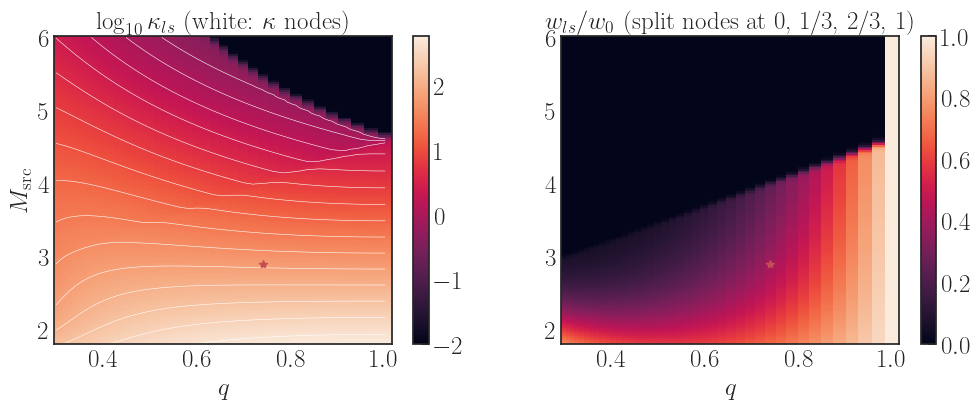

In [13]:
l = np.argmin(np.abs(np.exp(fo.l_src) - 2.89)); s = np.argmin(np.abs(np.exp(fo.lq) - 0.74))
Wk, Ww = np.asarray(my_kappa_weights(kap)[l, s]), np.asarray(my_split_weights(w)[l, s])
print(f"M_src = {np.exp(fo.l_src[l]):.3f}, q = {np.exp(fo.lq[s]):.3f}: m1 = {m1c[l, s]:.3f}, m2 = {m2c[l, s]:.3f}")
print(f"kappa_ls = {float(kap[l, s]):.2f};  kappa weights at nodes",
      [f"{kappa[c]:.1f}: {Wk[c]:.3f}" for c in np.nonzero(Wk)[0]])
print(f"w_ls = {float(w[l, s]):.4f} = {w_rel[l, s]:.3f} w0;  split weights at",
      [f"{f:.2f} w0: {v:.3f}" for f, v in zip(SPLIT_FRACTIONS, Ww)])
print("nonzero W (kappa x split) in this cell:", int((np.abs(np.asarray(W[l, s])) > 0).sum()))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
im = ax[0].pcolormesh(np.exp(fo.lq), np.exp(fo.l_src), np.log10(np.maximum(np.asarray(kap), 1e-2)), shading="auto")
ax[0].contour(np.exp(fo.lq), np.exp(fo.l_src), np.asarray(kap), levels=kappa[(kappa > 0.5) & (kappa < 1500)],
              colors="w", linewidths=0.4)
ax[0].set(xlabel=r"$q$", ylabel=r"$M_{\rm src}$", title=r"$\log_{10}\kappa_{ls}$ (white: $\kappa$ nodes)"); plt.colorbar(im, ax=ax[0])
im = ax[1].pcolormesh(np.exp(fo.lq), np.exp(fo.l_src), w_rel, vmin=0, vmax=1, shading="auto")
ax[1].set(xlabel=r"$q$", title=r"$w_{ls} / w_{0}$ (split nodes at 0, 1/3, 2/3, 1)"); plt.colorbar(im, ax=ax[1])
for a in ax:
    a.plot(np.exp(fo.lq[s]), np.exp(fo.l_src[l]), "r*")

## 6. Contract $q$ and κ **before** the redshift convolution

$$\hat P_{\ell r}=\sum_s\sum_{c,j} P_{\ell s}\,W_{\ell s,cj}\,\bar C_{rs,cj}\qquad(\texttt{einsum("lq,lqk,rqk->lr")},\ k=(c,j)).$$

Without spins $\bar C_{rs,cj}=C_{r,(s,cj)}$ (`_spin_coefficients` returns `_C[..., 0]`, of shape `(r, q, kappa x split)`).

**Why before the convolution?** $W$ depends on the source-frame mass $\ell$. After the redshift convolution only the detector-frame mass $d=\ell+j$ is left, and one $d$ mixes different $\ell$ (different $z$), so the EOS can no longer be applied. Conversely, once the contraction is done in the source frame, each cell carries its own κ and $w$ along when it is shifted; both are dimensionless and do not change with redshift, so this is exact.

The remaining steps are identical to chapter 03:

In [14]:
mass, rate = "uniform", "madau_dickinson"
n_sub = DEFAULT_N_SUB.get(mass, 4)                           # 4: the uniform model has hard edges

def P_cells(mp=None):
    m1, m2, jac = fo._mass_grid(n_sub)
    fnm, mdef = jp.MASS_MODELS[mass]
    P = fnm(m1, m2, {**mdef, **(mp or {}), "_w": d / n_sub}) * jac
    P = P.reshape(fo._n_l, n_sub, -1).mean(axis=1)
    P = P / jnp.sum(P * fo._cell)
    return P * fo._cell

def omega_from_Phat(P_hat, rp=None):                         # chapter 03, steps 4-9
    w = fo._zw * jp.RATE_MODELS[rate](jnp.asarray(fo.z), {**jp.RATE_DEFAULTS[rate], **(rp or {})})
    K = jnp.fft.irfft(jnp.fft.rfft(P_hat, n=fo._L1, axis=0) * jnp.fft.rfft(w, n=fo._L1)[:, None],
                      n=fo._L1, axis=0)[:fo._n_d] * fo._e4l
    c = jnp.fft.irfft(jnp.sum(jnp.fft.rfft(K[::-1], n=fo._L2, axis=0) * fo._FJ, axis=1), n=fo._L2)
    c = jnp.where(c > OMEGA_REL_CUT * jnp.max(c), c, 0.0)                   # round-off -> 0
    S = c[fo._n_d - 1:fo._n_d - 1 + fo._n_f]
    lnf = jnp.asarray(np.log(fo.freqs))
    S = jp.interp_uniform(lnf, fo.lnf[0], d, S)
    return S * jnp.exp(-A_PRE * (np.log(T_SUN) + lnf)) * 4 * np.pi ** 2 * jnp.exp(3 * lnf) / (3 * H0_SI ** 2)

Cbar = fo._spin_coefficients("gwtc5_default", {})             # no spins: C[..., 0], shape (r, q, kappa x split)
P_hat = jnp.einsum("lq,lqk,rqk->lr", P_cells(), W, Cbar)   # the ONLY tide-specific line
Omega_mine = omega_from_Phat(P_hat)
check("Omega with tides", Omega_mine, fo.omega(mass, rate))

Omega with tides               shape (996,)           max |diff| / max |ref| = 7.8e-16


np.float64(7.7920131725605e-16)

## 7. Exercise: the EOS and $\Omega$, and a first look at gradients

The larger $\Lambda_{1.4}$ (a stiffer EOS, larger neutron stars), the earlier the tidal taper and the lower the high-frequency $\Omega$; below 300 Hz there is hardly any difference. Finally, `jax.grad` gives $\partial\ln\Omega(1\,{\rm kHz})/\partial\ln\Lambda_{1.4}$: the gradient passes through the EOS, the interpolation weights, the einsum and two FFTs (more in chapter 06).

d ln Omega(1 kHz) / d ln Lambda_1.4 = -0.8573


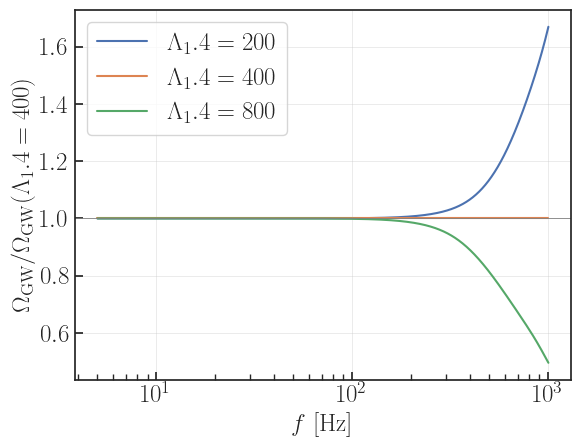

In [15]:
om = fo.make(mass, rate)
base = om()
for L14 in (200.0, 400.0, 800.0):
    plt.semilogx(fo.freqs, np.asarray(om(None, None, None, {"Lambda_14": L14}) / base), label=rf"$\Lambda_{1.4} = {L14:.0f}$")
plt.axhline(1, color="0.5", lw=0.6)
plt.xlabel(r"$f$ [Hz]"); plt.ylabel(r"$\Omega_{\rm GW} / \Omega_{\rm GW}(\Lambda_1.4 = 400)$"); plt.legend();

i1k = np.argmin(np.abs(fo.freqs - 1000.0))
dlnO = jax.grad(lambda lnL: jnp.log(om(None, None, None, {"Lambda_14": jnp.exp(lnL)})[i1k]))(jnp.log(400.0))
print(f"d ln Omega(1 kHz) / d ln Lambda_1.4 = {float(dlnO):.4f}")

## Summary

| Quantity | BBH without tides | BNS with tides |
|---|---|---|
| table columns | $s$ (121) | $(s,c,j)$ (41 × 24 × 4 = 3936) |
| column weights | $\sqrt{w_s}$ | $\sqrt{w_s}$ (no $1/(n_\kappa n_{\rm split})$) |
| tide nodes per $q$ | — | 24 κ × 4 split nodes (NRTidalv2: 24 κ) |
| rank | 8 | 85 (NRTidalv2: 83) |
| extra per call | — | EOS, $\kappa_{\ell s}$, $w_{\ell s}$, $W_{\ell s,cj}$ (242 × 41 × 96, ≤ 16 non-zero per cell), one einsum |

Four column labels, three ways of reading the table: $q$ is **integrated** with Simpson's rule, the spins are **averaged** with importance weights, and κ and the split are **interpolated** (cubic in $\ln\kappa$ and in $w$). The EOS (i.e. the new scale set by the neutron-star radius) appears only in $W_{\ell s,cj}$. It depends on the **source-frame** mass, so it must be contracted before the redshift convolution.

**Next chapter (06)**: `make()`, jit, gradients and numpyro: why FastOmega is differentiable everywhere, whether its gradients agree with finite differences, and how long a gradient takes.